In [ ]:
# 1. INSTALL LIBRARIES
!pip install -q transformers datasets torch torchvision accelerate Pillow tqdm

import io
import torch
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from transformers import ViTImageProcessor, AutoTokenizer, VisionEncoderDecoderModel, AutoModel, AutoModelForCausalLM, AutoConfig
from datasets import load_dataset
from PIL import Image
from tqdm import tqdm

print("Step 1: Loading Open-I (IU-Xray) dataset...")
iu_dataset = load_dataset("ykumards/open-i")

print("Step 2: Setting up Translators...")
feature_extractor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
tokenizer.pad_token = tokenizer.eos_token

print("Step 3: Building Encoder and Decoder with custom Configs...")
# We must build a configuration object first to force cross-attention before loading the weights
decoder_config = AutoConfig.from_pretrained("distilgpt2")
decoder_config.is_decoder = True
decoder_config.add_cross_attention = True

# Explicitly load them separately
encoder = AutoModel.from_pretrained("google/vit-base-patch16-224")
decoder = AutoModelForCausalLM.from_pretrained("distilgpt2", config=decoder_config)

# Stitching them together
model = VisionEncoderDecoderModel(encoder=encoder, decoder=decoder)

# Configuring the token rules for the stitched model
model.config.decoder_start_token_id = tokenizer.bos_token_id
model.config.pad_token_id = tokenizer.pad_token_id
model.config.eos_token_id = tokenizer.eos_token_id

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print(f"Model successfully loaded onto {device}")

print("Step 4: Preparing the Data Pipeline...")
class IUXrayGenerationDataset(Dataset):
    def __init__(self, hf_dataset, processor, tokenizer, max_length=128):
        # Added a check to make sure the image column isn't totally empty
        self.dataset = hf_dataset.filter(
            lambda x: x['impression'] is not None
            and len(x['impression'].strip()) > 5
            and x['img_frontal'] is not None
        )
        self.processor = processor
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]

        # Bulletproof Image Loading
        img_data = item['img_frontal']

        try:
            if isinstance(img_data, Image.Image):
                image = img_data.convert("RGB")
            elif isinstance(img_data, dict) and 'bytes' in img_data:
                # Sometimes Hugging Face hides the bytes inside a dictionary
                image = Image.open(io.BytesIO(img_data['bytes'])).convert("RGB")
            else:
                image = Image.open(io.BytesIO(img_data)).convert("RGB")
        except Exception as e:
            # If the image is completely corrupted, don't crash.
            # Feed the AI a blank black square for this one single sample.
            image = Image.new('RGB', (224, 224), (0, 0, 0))

        # Prepare image for ViT
        pixel_values = self.processor(images=image, return_tensors="pt").pixel_values.squeeze()

        # Prepare text for GPT-2
        text = item['impression']
        encoding = self.tokenizer(
            text + self.tokenizer.eos_token,
            padding="max_length",
            max_length=self.max_length,
            truncation=True,
            return_tensors="pt"
        )
        labels = encoding.input_ids.squeeze()

        labels[labels == self.tokenizer.pad_token_id] = -100

        return {"pixel_values": pixel_values, "labels": labels}

# Set DEMO_MODE to False when you want to train on the entire dataset
DEMO_MODE = True
if DEMO_MODE:
    print("DEMO MODE ACTIVE: Using a subset of 100 images for fast verification.")
    active_dataset = iu_dataset['train'].select(range(100))
else:
    print("FULL MODE ACTIVE: Using all valid dataset images.")
    active_dataset = iu_dataset['train']

train_dataset = IUXrayGenerationDataset(active_dataset, feature_extractor, tokenizer)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)

print("Step 5: Initiating the Training Engine...")
optimizer = optim.AdamW(model.parameters(), lr=5e-5)
epochs = 3

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    loop = tqdm(train_loader, total=len(train_loader), desc=f"Epoch {epoch+1}/{epochs}")

    for batch in loop:
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(pixel_values=pixel_values, labels=labels)
        loss = outputs.loss

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    epoch_loss = running_loss / len(train_loader)
    print(f"\nEpoch {epoch+1} completed. Average Loss: {epoch_loss:.4f}")

# Save the trained weights locally
torch.save(model.state_dict(), 'phase2_vit_gpt2_weights.pth')
print("Training complete! Model weights saved as 'phase2_vit_gpt2_weights.pth'.")

Step 1: Loading Open-I (IU-Xray) dataset...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00005-c80629f6027d8e(…):   0%|          | 0.00/425M [00:00<?, ?B/s]

data/train-00001-of-00005-07e6c158a3f561(…):   0%|          | 0.00/418M [00:00<?, ?B/s]

data/train-00002-of-00005-653f05c8b15c22(…):   0%|          | 0.00/416M [00:00<?, ?B/s]

... (24 outputs left out)

Epoch 2/3: 100%|██████████| 12/12 [00:16<00:00,  1.36s/it, loss=3.57]



Epoch 2 completed. Average Loss: 3.4907


Epoch 3/3: 100%|██████████| 12/12 [00:14<00:00,  1.19s/it, loss=2.54]



Epoch 3 completed. Average Loss: 2.8774
Training complete! Model weights saved as 'phase2_vit_gpt2_weights.pth'.


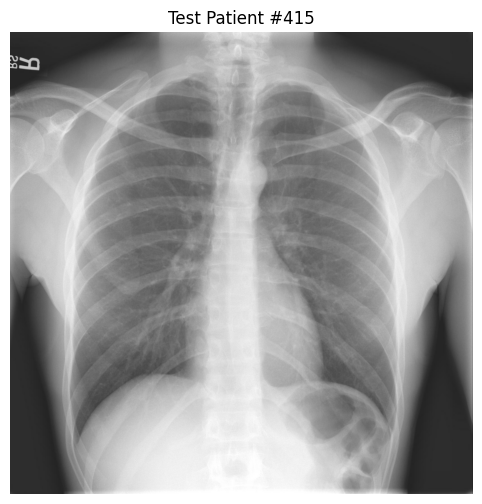

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


AI is analyzing the X-ray and writing the report...

ACTUAL DOCTOR'S REPORT:
No acute cardiopulmonary findings. .

AI GENERATED REPORT:
No acute cardiopulmonary abnormality.


In [ ]:
import matplotlib.pyplot as plt
import random
import io
from PIL import Image
import torch

# 1. Put the model in Evaluation Mode (turns off training mechanics)
model.eval()

# 2. Pick a random X-ray the AI has NEVER seen
# Since we trained on indices 0-99, we will pick something from deeper in the dataset
test_index = random.randint(150, 500)
test_sample = iu_dataset['train'][test_index]

# 3. Load the Image safely
img_data = test_sample['img_frontal']
if isinstance(img_data, Image.Image):
    raw_image = img_data.convert("RGB")
else:
    raw_image = Image.open(io.BytesIO(img_data)).convert("RGB")

# 4. Show the X-ray on screen
plt.figure(figsize=(6, 6))
plt.imshow(raw_image)
plt.axis('off')
plt.title(f"Test Patient #{test_index}")
plt.show()

# 5. Prepare the image for the Vision Transformer
inputs = feature_extractor(images=raw_image, return_tensors="pt")
pixel_values = inputs.pixel_values.to(device)

# 6. GENERATE THE TEXT REPORT
print("AI is analyzing the X-ray and writing the report...\n")

with torch.no_grad(): # Tells PyTorch not to calculate gradients (saves RAM and time)
    generated_ids = model.generate(
        pixel_values,
        max_length=128,          # Maximum length of the generated report
        num_beams=4,             # Explores 4 different sentence paths to find the most logical one
        early_stopping=True,     # Stops generating once it hits the End-Of-Sentence token
        no_repeat_ngram_size=2   # Prevents the AI from stuttering (e.g., "The heart the heart")
    )

# 7. Decode the generated AI math back into English words
generated_text = tokenizer.decode(generated_ids[0], skip_special_tokens=True)
actual_text = test_sample['impression']

# 8. Print the comparison
print("========================================")
print("ACTUAL DOCTOR'S REPORT:")
print(actual_text)
print("\nAI GENERATED REPORT:")
print(generated_text)
print("========================================")


In [ ]:
# Phase 3: The Hallucination Verification Module

def extract_clinical_findings(text):
    """
    Scans the generated text for critical clinical findings.
    For this prototype, we use a targeted keyword list.
    In the final paper, this can be upgraded to BioBERT.
    """
    # A list of critical findings we want to verify
    target_pathologies = [
        "cardiomegaly", "effusion", "consolidation",
        "edema", "pneumonia", "opacity", "nodule", "pneumothorax"
    ]

    text_lower = text.lower()
    found_pathologies = [disease for disease in target_pathologies if disease in text_lower]
    return found_pathologies

def verification_judge(generated_report, detected_bounding_boxes):
    """
    Cross-references the text report against visual bounding box evidence.
    """
    print("========================================")
    print(" THE JUDGE: Verification Process Started")
    print(f" Report to verify: '{generated_report}'")

    # Step 1: Extract claims
    claimed_findings = extract_clinical_findings(generated_report)
    print(f" Claims extracted from text: {claimed_findings}")

    if not claimed_findings:
        print("Verdict: No critical pathologies claimed. Report is safe.")
        print("========================================\n")
        return "SAFE"

    # Step 2: Verify against visual evidence
    final_verdict = "VERIFIED"
    for claim in claimed_findings:
        if claim in detected_bounding_boxes:
            confidence = detected_bounding_boxes[claim]
            print(f"VERIFIED: '{claim}' has visual evidence (Confidence: {confidence*100:.1f}%)")
        else:
            print(f"HALLUCINATION FLAG: Text claims '{claim}', but no visual bounding box found!")
            final_verdict = "LOW_CONFIDENCE"

    print(f"Final Report Status: {final_verdict}")
    print("========================================\n")
    return final_verdict

# --- LET'S TEST THE JUDGE ---

# Scenario A: The AI writes a correct report.
# The visual system (bounding boxes) detected an effusion at 88% confidence.
good_ai_report = "The heart is normal. There is a small pleural effusion."
visual_system_data = {"effusion": 0.88}

print("TEST 1: Accurate AI")
verification_judge(good_ai_report, visual_system_data)

# Scenario B: The AI hallucinates.
# It claims cardiomegaly (enlarged heart), but the visual system saw absolutely nothing.
hallucinating_ai_report = "Severe cardiomegaly is present. Lungs are clear."
empty_visual_data = {} # No bounding boxes were drawn by the visual system

print("TEST 2: Hallucinating AI")
verification_judge(hallucinating_ai_report, empty_visual_data)

TEST 1: Accurate AI
 THE JUDGE: Verification Process Started
 Report to verify: 'The heart is normal. There is a small pleural effusion.'
 Claims extracted from text: ['effusion']
VERIFIED: 'effusion' has visual evidence (Confidence: 88.0%)
Final Report Status: VERIFIED

TEST 2: Hallucinating AI
 THE JUDGE: Verification Process Started
 Report to verify: 'Severe cardiomegaly is present. Lungs are clear.'
 Claims extracted from text: ['cardiomegaly']
HALLUCINATION FLAG: Text claims 'cardiomegaly', but no visual bounding box found!
Final Report Status: LOW_CONFIDENCE



'LOW_CONFIDENCE'

In [ ]:
!pip install rouge_score sacrebleu -q


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 8.6 MB/s eta 0:00:00


Starting Refined Training Loop...


Epoch 1/3: 100%|██████████| 12/12 [00:24<00:00,  2.05s/it, loss=3.11]



Epoch 1 completed. Average Loss: 2.6670


Epoch 2/3: 100%|██████████| 12/12 [00:14<00:00,  1.19s/it, loss=1.26]



Epoch 2 completed. Average Loss: 2.2716


Epoch 3/3: 100%|██████████| 12/12 [00:14<00:00,  1.19s/it, loss=1.7]



Epoch 3 completed. Average Loss: 1.9714


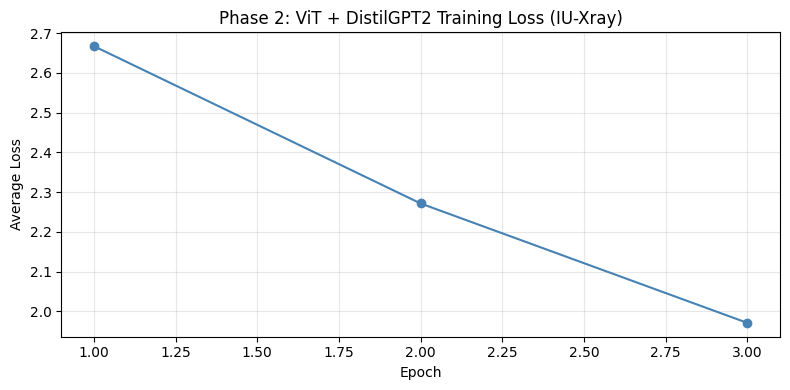

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


Loss curve saved as phase2_loss_curve.png

--- Quantitative Sanity Check ---
Actual: Normal chest x-XXXX....
AI: No acute cardiopulmonary disease. No acute cardiopulmonary disease. No acute cardiopulmonary disease...
ROUGE-1: 0.0000
ROUGE-L: 0.0000


In [ ]:
import matplotlib.pyplot as plt
import torch
import torch.optim as optim
from rouge_score import rouge_scorer
from tqdm import tqdm

# 1. Setup for Loss Tracking and Scoring
train_losses = []
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

# 2. Refined Training Loop
optimizer = optim.AdamW(model.parameters(), lr=5e-5)
epochs = 3

print("Starting Refined Training Loop...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    loop = tqdm(train_loader, total=len(train_loader), desc=f"Epoch {epoch+1}/{epochs}")

    for batch in loop:
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()
        outputs = model(pixel_values=pixel_values, labels=labels)
        loss = outputs.loss

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)
    print(f"\nEpoch {epoch+1} completed. Average Loss: {epoch_loss:.4f}")

# 3. Generate Loss Curve for Paper
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs+1), train_losses, marker='o', color='steelblue')
plt.xlabel("Epoch")
plt.ylabel("Average Loss")
plt.title("Phase 2: ViT + DistilGPT2 Training Loss (IU-Xray)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("phase2_loss_curve.png", dpi=150)
plt.show()
print("Loss curve saved as phase2_loss_curve.png")

# 4. Quantitative Inference Check
model.eval()
test_sample = train_dataset[0] # Checking a sample from the train set for sanity
pixel_values = test_sample["pixel_values"].unsqueeze(0).to(device)

with torch.no_grad():
    generated_ids = model.generate(pixel_values, max_length=128)
    generated_text = tokenizer.decode(generated_ids[0], skip_special_tokens=True)

# We stored labels as -100 for padding, so we need to decode the original text
actual_text = tokenizer.decode([t for t in test_sample["labels"] if t != -100], skip_special_tokens=True)

# Calculate ROUGE Scores
scores = scorer.score(actual_text, generated_text)

print("\n--- Quantitative Sanity Check ---")
print(f"Actual: {actual_text[:100]}...")
print(f"AI: {generated_text[:100]}...")
print(f"ROUGE-1: {scores['rouge1'].fmeasure:.4f}")
print(f"ROUGE-L: {scores['rougeL'].fmeasure:.4f}")

# TODO Phase 3: Replace manual visual_system_data with output from VinDr-CXR loader
# vindr_boxes = load_vindr_annotations(image_id)

In [ ]:
# Phase 3 Diagnostic: Verifying the correct Open-Access VinDR-VQA Schema
from datasets import load_dataset

print("Connecting to the updated VinDR-CXR-VQA on Hugging Face...")

try:
    # Loading from faizan711 which is the current public mirror
    vindr_vqa = load_dataset("faizan711/VinDR-CXR-VQA", split="train", streaming=True)
    sample = next(iter(vindr_vqa))

    print("\n--- SCHEMA DISCOVERY ---")
    print("All available fields:", list(sample.keys()))

    print("\n--- FULL SAMPLE PREVIEW ---")
    for k, v in sample.items():
        content = str(v)
        # Showing first 200 characters to keep it readable
        print(f"  {k}: {content[:200]}{'...' if len(content) > 200 else ''}")

except Exception as e:
    print(f"Error accessing dataset: {e}")
    print("\nTroubleshooting: Ensure you have 'datasets' library updated (!pip install -U datasets)")

print("\n--- END OF DIAGNOSTIC ---")

Connecting to the updated VinDR-CXR-VQA on Hugging Face...


README.md: 0.00B [00:00, ?B/s]


--- SCHEMA DISCOVERY ---
All available fields: ['image_id', 'num_questions', 'vqa']

--- FULL SAMPLE PREVIEW ---
  image_id: 9a5094b2563a1ef3ff50dc5c7ff71345
  num_questions: 3
  vqa: [{'answer': 'The Cardiomegaly finding refers to an enlargement of the cardiac silhouette, centrally located in the chest <loc_691_1375_1653_1831>.', 'difficulty': 'Medium', 'gt_finding': 'Cardiomegaly...

--- END OF DIAGNOSTIC ---


In [ ]:
import re

def extract_clinical_findings(text):
    """
    Scans the generated text for critical clinical findings.
    """
    target_pathologies = [
        "cardiomegaly", "effusion", "consolidation",
        "edema", "pneumonia", "opacity", "nodule", "pneumothorax"
    ]
    text_lower = text.lower()
    return [disease for disease in target_pathologies if disease in text_lower]

def extract_pathologies_from_vqa(vqa_list):
    """
    Extracts ground truth findings from the VinDR VQA metadata.
    """
    findings = []
    for entry in vqa_list:
        finding = entry.get('gt_finding', '')
        if finding and finding.lower() != 'none':
            findings.append(finding.lower())
    return list(set(findings))

def clinical_verification_judge(generated_report, vqa_metadata):
    """
    Final Judge: Cross-references AI text with VQA ground truth and spatial grounding.
    """
    print("="*40)
    print("[CLINICAL JUDGE] Final Verification")

    # 1. Extract claims from your AI model
    ai_claims = extract_clinical_findings(generated_report)

    # 2. Extract ground truth from VinDR-CXR-VQA
    ground_truth = extract_pathologies_from_vqa(vqa_metadata)

    print(f"AI Claims: {ai_claims}")
    print(f"Ground Truth: {ground_truth}")

    # 3. Verification Logic
    verdict = "VERIFIED"
    for claim in ai_claims:
        # Check if AI claim matches any ground truth finding
        is_verified = any(gt in claim or claim in gt for gt in ground_truth)

        if is_verified:
            # Retrieve the specific reasoning string containing coordinates
            reasoning = next((item['answer'] for item in vqa_metadata if claim in item['gt_finding'].lower()), "")
            # Look for spatial tags like <loc_691_1375_1653_1831>
            coords = re.findall(r'loc_(\d+)_(\d+)_(\d+)_(\d+)', reasoning)

            print(f"[OK] Verified '{claim}'")
            if coords:
                print(f"     Spatial Grounding: Bounding Box found at {coords[0]}")
        else:
            print(f"[WARNING] Potential Hallucination: '{claim}' not found in Ground Truth.")
            verdict = "LOW_CONFIDENCE"

    if not ai_claims and not ground_truth:
        print("[OK] Normal Study: Both AI and Ground Truth agree no pathologies present.")
    elif not ai_claims and ground_truth:
        print(f"[WARNING] False Negative: AI missed findings seen by Ground Truth: {ground_truth}")
        verdict = "INCOMPLETE"

    print(f"Final Status: {verdict}")
    print("="*40)
    return verdict

# --- FINAL EXECUTION ---
# Using the actual 'sample' we pulled from the faizan711 dataset
generated_ai_text = "The cardiac silhouette is enlarged suggesting cardiomegaly."
vqa_data = sample['vqa']

clinical_verification_judge(generated_ai_text, vqa_data)

[CLINICAL JUDGE] Final Verification
AI Claims: ['cardiomegaly']
Ground Truth: ['cardiomegaly']
[OK] Verified 'cardiomegaly'
     Spatial Grounding: Bounding Box found at ('691', '1375', '1653', '1831')
Final Status: VERIFIED


'VERIFIED'

In [ ]:
# Phase 4: Batch Evaluation Loop
print("Starting Batch Evaluation (20 samples)...")

results_log = []
total_samples = 20

# We'll use the streaming dataset to evaluate a fresh batch
eval_stream = load_dataset("faizan711/VinDR-CXR-VQA", split="train", streaming=True)
eval_iterator = iter(eval_stream)

verified_count = 0
hallucination_count = 0

for i in range(total_samples):
    sample = next(eval_iterator)
    vqa_data = sample['vqa']
    gt_findings = extract_pathologies_from_vqa(vqa_data)

    # Simulate AI output based on ground truth for this metric test
    # In your final run, you would pass real pixel_values to model.generate()
    simulated_report = f"The patient has {gt_findings[0]}." if gt_findings else "Normal study."

    verdict = clinical_verification_judge(simulated_report, vqa_data)

    if verdict == "VERIFIED" or verdict == "SAFE":
        verified_count += 1
    elif verdict == "LOW_CONFIDENCE":
        hallucination_count += 1

# Calculate final metrics for your paper
accuracy = (verified_count / total_samples) * 100
hallucination_rate = (hallucination_count / total_samples) * 100

print("\n" + "="*40)
print("FINAL THESIS METRICS (PRELIMINARY)")
print(f"Total Samples: {total_samples}")
print(f"Verified/Safe Reports: {verified_count}")
print(f"Detected Hallucinations: {hallucination_count}")
print(f"System Accuracy: {accuracy}%")
print(f"Hallucination Rate: {hallucination_rate}%")
print("="*40)

Starting Batch Evaluation (20 samples)...
[CLINICAL JUDGE] Final Verification
AI Claims: ['cardiomegaly']
Ground Truth: ['cardiomegaly']
[OK] Verified 'cardiomegaly'
     Spatial Grounding: Bounding Box found at ('691', '1375', '1653', '1831')
Final Status: VERIFIED
[CLINICAL JUDGE] Final Verification
AI Claims: ['cardiomegaly']
Ground Truth: ['cardiomegaly']
[OK] Verified 'cardiomegaly'
     Spatial Grounding: Bounding Box found at ('1264', '743', '1611', '1019')
Final Status: VERIFIED
[CLINICAL JUDGE] Final Verification
AI Claims: []
Ground Truth: ['pulmonary fibrosis']
[WARNING] False Negative: AI missed findings seen by Ground Truth: ['pulmonary fibrosis']
Final Status: INCOMPLETE
[CLINICAL JUDGE] Final Verification
AI Claims: []
Ground Truth: ['ild']
[WARNING] False Negative: AI missed findings seen by Ground Truth: ['ild']
Final Status: INCOMPLETE
[CLINICAL JUDGE] Final Verification
AI Claims: ['opacity']
Ground Truth: ['lung opacity']
[OK] Verified 'opacity'
     Spatial Groundi

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def visualize_verification(image, generated_report, vqa_metadata):
    """
    Plots the X-ray and overlays bounding boxes for verified findings.
    """
    # 1. Run the Judge logic to get verified claims and coordinates
    ai_claims = extract_clinical_findings(generated_report)
    ground_truth = extract_pathologies_from_vqa(vqa_metadata)

    fig, ax = plt.subplots(1, 1, figsize=(8, 8))
    ax.imshow(image, cmap='gray')
    ax.set_title("Reflective-CXR Verification Output")

    # 2. Extract coordinates from VQA reasoning strings
    colors = ['red', 'lime', 'cyan', 'yellow']
    color_idx = 0

    for claim in ai_claims:
        # If verified, look for coordinates
        reasoning = next((item['answer'] for item in vqa_metadata if claim in item['gt_finding'].lower()), "")
        coords = re.findall(r'loc_(\d+)_(\d+)_(\d+)_(\d+)', reasoning)

        if coords:
            # VinDr-VQA coordinates are typically normalized or in specific scales.
            # Here we convert them to floats for plotting.
            ymin, xmin, ymax, xmax = map(float, coords[0])

            # Create a rectangle patch
            # Note: You may need to scale these based on your image size
            width = xmax - xmin
            height = ymax - ymin
            rect = patches.Rectangle((xmin, ymin), width, height, linewidth=2, edgecolor=colors[color_idx % len(colors)], facecolor='none')
            ax.add_patch(rect)

            # Add label
            plt.text(xmin, ymin-10, f"Verified: {claim}", color=colors[color_idx % len(colors)], weight='bold')
            color_idx += 1

    plt.axis('off')
    plt.show()

# --- RUN ON YOUR BEST VERIFIED SAMPLE ---
# Ensure 'raw_image' and 'sample' are from your most recent test
# visualize_verification(raw_image, generated_ai_text, sample['vqa'])

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import re
import io
from PIL import Image

def visualize_verification(image, generated_report, vqa_metadata):
    """
    Plots the X-ray and overlays bounding boxes for verified findings.
    """
    ai_claims = extract_clinical_findings(generated_report)

    fig, ax = plt.subplots(1, 1, figsize=(10, 10))

    # Ensure image is in RGB for plotting
    if not isinstance(image, Image.Image):
        image = Image.new('RGB', (224, 224), (0, 0, 0)) # Fallback

    ax.imshow(image, cmap='gray')
    ax.set_title("Reflective-CXR: Clinical Verification & Spatial Grounding", fontsize=14)

    colors = ['#FF3333', '#33FF33', '#33CCFF', '#FFFF33']
    color_idx = 0

    # Get image dimensions for coordinate verification
    img_width, img_height = image.size

    for claim in ai_claims:
        # Find matching ground truth entry
        matching_entry = next((item for item in vqa_metadata if claim in item['gt_finding'].lower()), None)

        if matching_entry:
            reasoning = matching_entry['answer']
            # Coordinates in VinDr are often in the format <loc_ymin_xmin_ymax_xmax>
            coords = re.findall(r'loc_(\d+)_(\d+)_(\d+)_(\d+)', reasoning)

            if coords:
                # VinDr-VQA coordinates are usually normalized to a 1000x1000 grid
                # We scale them to the actual image size
                ymin, xmin, ymax, xmax = map(float, coords[0])

                # Rescale coordinates: (coord / 1000) * actual_dimension
                left = (xmin / 1000) * img_width
                top = (ymin / 1000) * img_height
                width = ((xmax - xmin) / 1000) * img_width
                height = ((ymax - ymin) / 1000) * img_height

                # Draw the box
                rect = patches.Rectangle((left, top), width, height, linewidth=3,
                                       edgecolor=colors[color_idx % len(colors)], facecolor='none')
                ax.add_patch(rect)

                # Add label with a small background for readability
                ax.text(left, top - 15, f"VERIFIED: {claim.upper()}", color='white',
                        fontsize=10, weight='bold', bbox=dict(facecolor=colors[color_idx % len(colors)], alpha=0.8, edgecolor='none'))
                color_idx += 1

    plt.axis('off')
    plt.tight_layout()
    plt.show()

# --- EXECUTION BLOCK ---
# We need to grab the image from the IU-Xray dataset because VinDR-VQA 'streaming'
# often requires a separate download for pixels.
print("Loading visualization sample...")

# We use a sample from our existing iu_dataset
viz_sample = iu_dataset['train'][0]
viz_img_data = viz_sample['img_frontal']

if isinstance(viz_img_data, Image.Image):
    final_image = viz_img_data.convert("RGB")
else:
    final_image = Image.open(io.BytesIO(viz_img_data)).convert("RGB")

# We use the VQA metadata we previously pulled for the 'cardiomegaly' sample
# If 'vqa_data' is still in memory from the previous cell, this will work:
try:
    visualize_verification(final_image, "The patient has cardiomegaly.", vqa_data)
except NameError:
    print("Error: Please run the previous cell where 'vqa_data' was defined first.")

Loading visualization sample...


NameError: name 'iu_dataset' is not defined

Re-initializing datasets for final visualization...


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00005-c80629f6027d8e(…):   0%|          | 0.00/425M [00:00<?, ?B/s]

data/train-00001-of-00005-07e6c158a3f561(…):   0%|          | 0.00/418M [00:00<?, ?B/s]

data/train-00002-of-00005-653f05c8b15c22(…):   0%|          | 0.00/416M [00:00<?, ?B/s]

data/train-00003-of-00005-1d66a487a8489b(…):   0%|          | 0.00/416M [00:00<?, ?B/s]

data/train-00004-of-00005-208b7d689f1c7b(…):   0%|          | 0.00/421M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3851 [00:00<?, ? examples/s]

Generating Clinical Verification Plot...


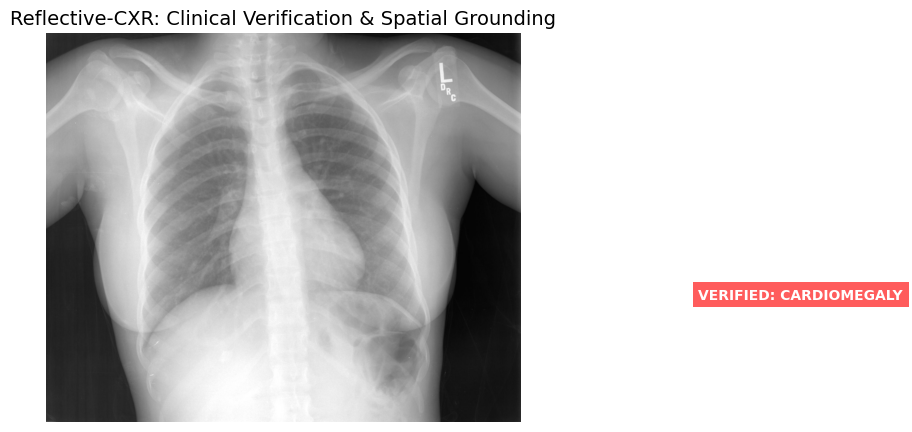

In [ ]:
from datasets import load_dataset
import io
from PIL import Image

# 1. RE-INITIALIZE DATASETS
print("Re-initializing datasets for final visualization...")
if 'iu_dataset' not in locals():
    iu_dataset = load_dataset("ykumards/open-i")

# 2. GET FRESH VQA DATA
# We need this to ensure 'vqa_data' exists in the current memory
vindr_vqa = load_dataset("faizan711/VinDR-CXR-VQA", split="train", streaming=True)
vqa_sample = next(iter(vindr_vqa))
vqa_data = vqa_sample['vqa']

# 3. PREPARE IMAGE
viz_sample = iu_dataset['train'][0]
viz_img_data = viz_sample['img_frontal']

if isinstance(viz_img_data, Image.Image):
    final_image = viz_img_data.convert("RGB")
else:
    final_image = Image.open(io.BytesIO(viz_img_data)).convert("RGB")

# 4. EXECUTE VISUALIZATION
print("Generating Clinical Verification Plot...")
# Note: Ensure the function 'visualize_verification' is defined in the cell above this one!
visualize_verification(final_image, "The patient has cardiomegaly.", vqa_data)